In [11]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/config.json
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/X_train_pre.csv
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/camembert_training_history.csv
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/images_analysis.csv
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/lang.csv
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/translation.json
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/df_train_clean.csv
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/label_mapping.json
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/df_train.csv
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/df_val.csv
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/tokenizer.json
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/tokenizer_config.json
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/vgg16_best.pth
/kaggle/input/datasets/tarikouhsine/raku

KeyboardInterrupt: 

In [12]:
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.metrics import f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from itertools import product as itertools_product

INPUT_DIR = Path('/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed')
WORK_DIR  = Path('/kaggle/working')

print("✅ Imports OK")

✅ Imports OK


In [13]:
# Probabilités CamemBERT
camembert_val_probs  = np.load(INPUT_DIR / 'camembert_val_probs.npy')
camembert_test_probs = np.load(INPUT_DIR / 'camembert_test_probs.npy')

# Probabilités VGG16
vgg16_val_probs  = np.load(INPUT_DIR / 'vgg16_val_probs.npy')
vgg16_test_probs = np.load(INPUT_DIR / 'vgg16_test_probs.npy')

# Labels réels
df_val  = pd.read_csv(INPUT_DIR / 'df_val.csv',  index_col=0)
df_test = pd.read_csv(INPUT_DIR / 'df_test.csv', index_col=0)

classes   = sorted(df_val['prdtypecode'].unique())
class2idx = {c: i for i, c in enumerate(classes)}
idx2class = {i: c for i, c in enumerate(classes)}

y_val  = df_val['prdtypecode'].map(class2idx).values
y_test = df_test['prdtypecode'].map(class2idx).values

print(f"✅ Probabilités chargées")
print(f"   CamemBERT val  : {camembert_val_probs.shape}")
print(f"   CamemBERT test : {camembert_test_probs.shape}")
print(f"   VGG16 val      : {vgg16_val_probs.shape}")
print(f"   VGG16 test     : {vgg16_test_probs.shape}")

# Scores individuels de référence
f1_camembert_val = f1_score(y_val,  np.argmax(camembert_val_probs,  axis=1), average='weighted')
f1_camembert_test= f1_score(y_test, np.argmax(camembert_test_probs, axis=1), average='weighted')
f1_vgg16_val     = f1_score(y_val,  np.argmax(vgg16_val_probs,      axis=1), average='weighted')
f1_vgg16_test    = f1_score(y_test, np.argmax(vgg16_test_probs,     axis=1), average='weighted')

print(f"\n📊 Scores individuels :")
print(f"   CamemBERT → Val: {f1_camembert_val:.4f} | Test: {f1_camembert_test:.4f}")
print(f"   VGG16     → Val: {f1_vgg16_val:.4f} | Test: {f1_vgg16_test:.4f}")

✅ Probabilités chargées
   CamemBERT val  : (8492, 27)
   CamemBERT test : (8492, 27)
   VGG16 val      : (8492, 27)
   VGG16 test     : (8492, 27)

📊 Scores individuels :
   CamemBERT → Val: 0.8826 | Test: 0.8777
   VGG16     → Val: 0.6504 | Test: 0.6521


In [14]:
# Test de toutes les combinaisons de poids (w_text + w_image = 1)
weights = np.arange(0.0, 1.05, 0.05).round(2)
results = []

print("⏳ Grid search sur les poids de fusion...\n")

for w_camembert in weights:
    w_vgg16 = round(1.0 - w_camembert, 2)

    combined_val  = (w_camembert * camembert_val_probs +
                     w_vgg16     * vgg16_val_probs)
    preds_val     = np.argmax(combined_val, axis=1)
    f1_val        = f1_score(y_val, preds_val, average='weighted')

    results.append({
        'w_camembert': w_camembert,
        'w_vgg16'    : w_vgg16,
        'f1_val'     : round(f1_val, 4)
    })

df_grid = pd.DataFrame(results).sort_values('f1_val', ascending=False)

print("Top 10 combinaisons (sur Val) :")
print(df_grid.head(10).to_string(index=False))

best_row        = df_grid.iloc[0]
best_w_camembert = best_row['w_camembert']
best_w_vgg16    = best_row['w_vgg16']
print(f"\n🏆 Meilleurs poids :")
print(f"   CamemBERT : {best_w_camembert}")
print(f"   VGG16     : {best_w_vgg16}")
print(f"   F1 Val    : {best_row['f1_val']:.4f}")

⏳ Grid search sur les poids de fusion...

Top 10 combinaisons (sur Val) :
 w_camembert  w_vgg16  f1_val
        0.65     0.35  0.8876
        0.70     0.30  0.8870
        0.60     0.40  0.8869
        0.75     0.25  0.8862
        0.80     0.20  0.8855
        0.85     0.15  0.8848
        0.90     0.10  0.8847
        0.55     0.45  0.8839
        0.95     0.05  0.8833
        1.00     0.00  0.8826

🏆 Meilleurs poids :
   CamemBERT : 0.65
   VGG16     : 0.35
   F1 Val    : 0.8876


In [15]:
# Application des meilleurs poids sur le test set
combined_test = (best_w_camembert * camembert_test_probs +
                 best_w_vgg16     * vgg16_test_probs)
preds_test    = np.argmax(combined_test, axis=1)
f1_test_fusion = f1_score(y_test, preds_test, average='weighted')

# Résumé complet
print("=" * 55)
print("RÉSULTATS FINAUX — COMPARAISON COMPLÈTE")
print("=" * 55)
print(f"   TF-IDF + SVC                → {0.8121:.4f}")
print(f"   VGG16 (image seul)          → {f1_vgg16_test:.4f}")
print(f"   CamemBERT (texte seul)      → {f1_camembert_test:.4f}")
print(f"   Fusion ({best_w_camembert}/{best_w_vgg16})              → {f1_test_fusion:.4f}")
print("=" * 55)
gain = f1_test_fusion - f1_camembert_test
print(f"   Gain fusion vs CamemBERT seul : {gain:+.4f}")

RÉSULTATS FINAUX — COMPARAISON COMPLÈTE
   TF-IDF + SVC                → 0.8121
   VGG16 (image seul)          → 0.6521
   CamemBERT (texte seul)      → 0.8777
   Fusion (0.65/0.35)              → 0.8877
   Gain fusion vs CamemBERT seul : +0.0100


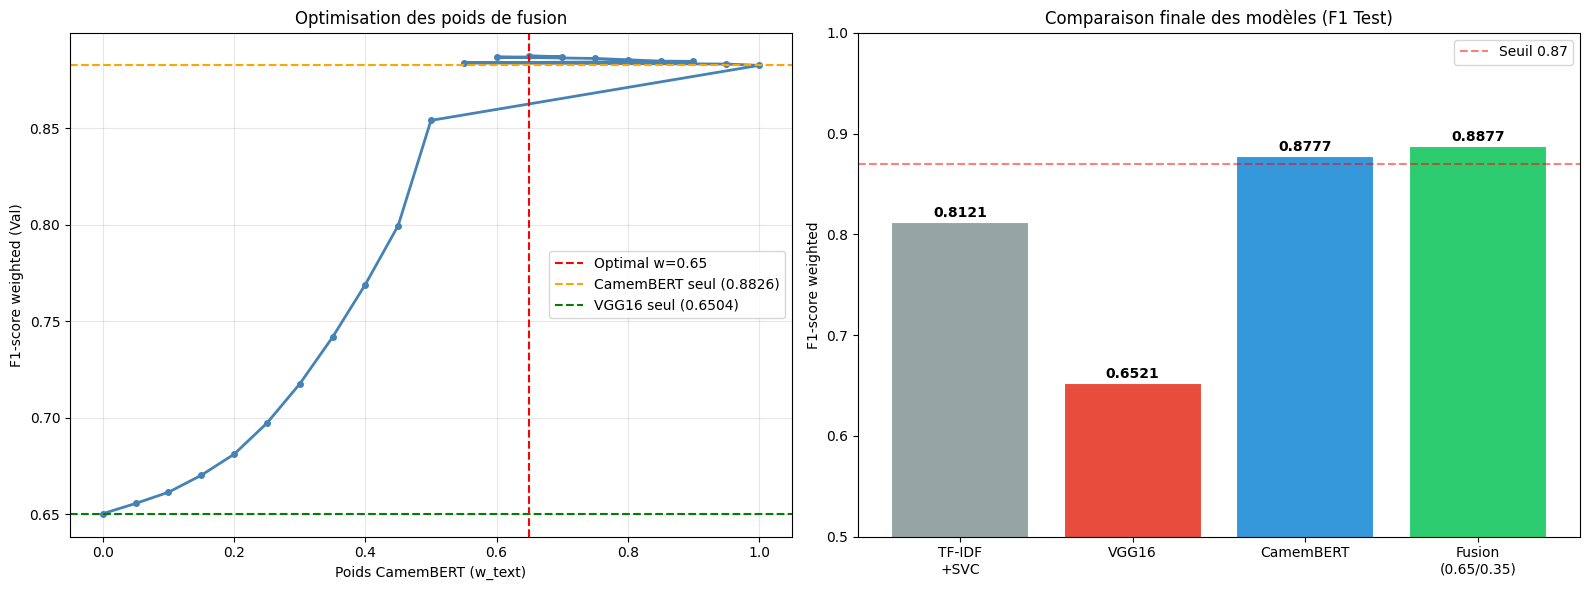

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Courbe F1 selon poids
axes[0].plot(df_grid['w_camembert'], df_grid['f1_val'],
             color='steelblue', linewidth=2, marker='o', markersize=4)
axes[0].axvline(best_w_camembert, color='red', linestyle='--',
                label=f'Optimal w={best_w_camembert}')
axes[0].axhline(f1_camembert_val, color='orange', linestyle='--',
                label=f'CamemBERT seul ({f1_camembert_val:.4f})')
axes[0].axhline(f1_vgg16_val, color='green', linestyle='--',
                label=f'VGG16 seul ({f1_vgg16_val:.4f})')
axes[0].set_xlabel("Poids CamemBERT (w_text)")
axes[0].set_ylabel("F1-score weighted (Val)")
axes[0].set_title("Optimisation des poids de fusion")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Barplot comparaison
models_comp = {
    'TF-IDF\n+SVC'  : 0.8121,
    'VGG16'         : f1_vgg16_test,
    'CamemBERT'     : f1_camembert_test,
    f'Fusion\n({best_w_camembert}/{best_w_vgg16})' : f1_test_fusion,
}
colors = ['#95a5a6', '#e74c3c', '#3498db', '#2ecc71']
bars = axes[1].bar(models_comp.keys(), models_comp.values(),
                   color=colors, edgecolor='white', linewidth=1.5)
axes[1].set_ylim(0.5, 1.0)
axes[1].set_title("Comparaison finale des modèles (F1 Test)")
axes[1].set_ylabel("F1-score weighted")
axes[1].axhline(0.87, color='red', linestyle='--', alpha=0.5, label='Seuil 0.87')
axes[1].legend()
for bar, val in zip(bars, models_comp.values()):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                 f'{val:.4f}', ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig(WORK_DIR / 'fusion_results.png', dpi=150, bbox_inches='tight')
plt.show()

                precision    recall  f1-score   support

    Livre occ.       0.77      0.68      0.73       311
     Jeu vidéo       0.83      0.84      0.84       251
Access.Console       0.86      0.94      0.90       168
       Console       0.92      0.92      0.92        83
      Figurine       0.78      0.86      0.82       267
   Carte Coll.       0.96      0.96      0.96       396
   Jeu Plateau       0.69      0.66      0.68        76
    Jouet enf.       0.83      0.72      0.77       487
   Jeu société       0.71      0.69      0.70       207
    Jouet tech       0.97      0.98      0.98       505
   Chaussettes       0.98      1.00      0.99        81
      Jeu ext.       0.79      0.90      0.84       249
          Bébé       0.84      0.87      0.85       324
 Mobilier int.       0.92      0.84      0.88       507
       Chambre       0.91      0.96      0.94       431
       Cuisine       0.89      0.96      0.92        81
     Déco int.       0.86      0.85      0.85  

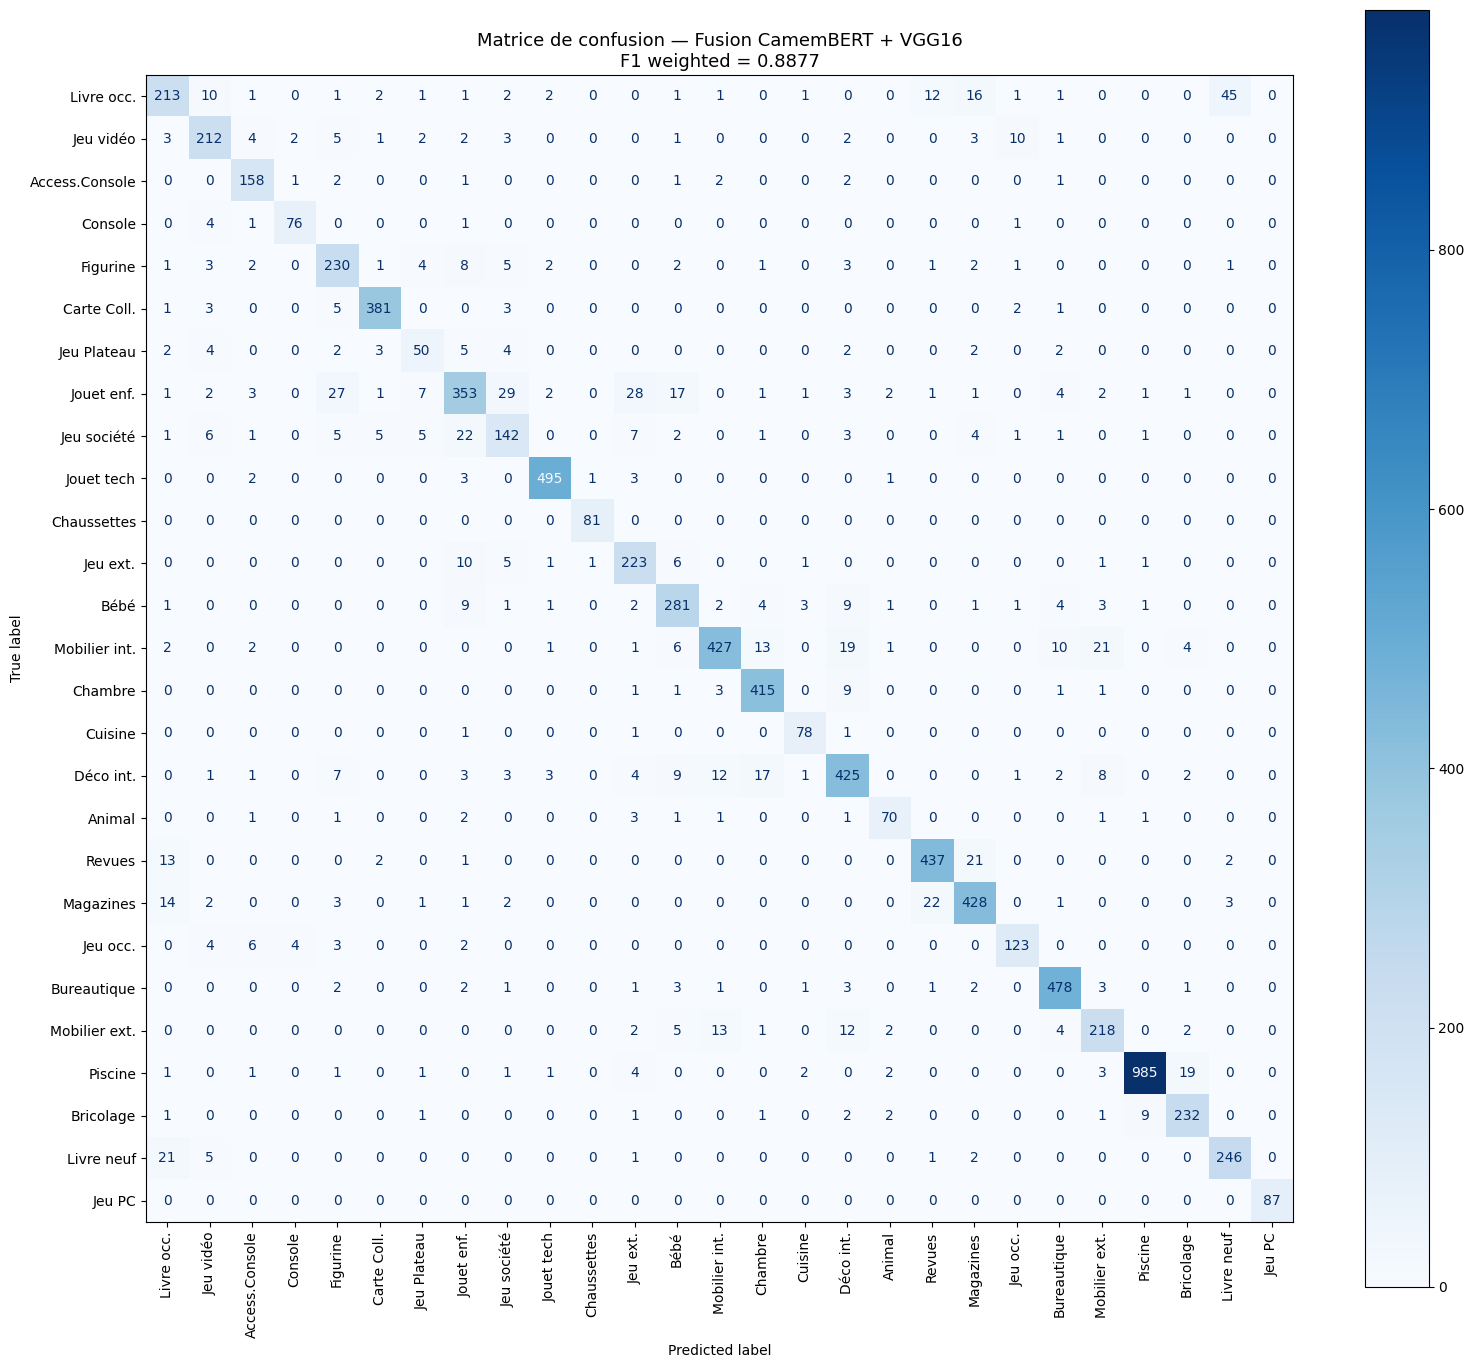

In [17]:
prdcodetype2label = {
    10:'Livre occ.', 40:'Jeu vidéo', 50:'Access.Console',
    60:'Console', 1140:'Figurine', 1160:'Carte Coll.',
    1180:'Jeu Plateau', 1280:'Jouet enf.', 1281:'Jeu société',
    1300:'Jouet tech', 1301:'Chaussettes', 1302:'Jeu ext.',
    1320:'Bébé', 1560:'Mobilier int.', 1920:'Chambre',
    1940:'Cuisine', 2060:'Déco int.', 2220:'Animal',
    2280:'Revues', 2403:'Magazines', 2462:'Jeu occ.',
    2522:'Bureautique', 2582:'Mobilier ext.', 2583:'Piscine',
    2585:'Bricolage', 2705:'Livre neuf', 2905:'Jeu PC',
}
labels_str = [prdcodetype2label.get(classes[i], str(classes[i]))
              for i in range(len(classes))]

print(classification_report(y_test, preds_test, target_names=labels_str))

# Matrice de confusion
cm = confusion_matrix(y_test, preds_test)
fig, ax = plt.subplots(figsize=(16, 14))
ConfusionMatrixDisplay(confusion_matrix=cm,
                       display_labels=labels_str).plot(
    ax=ax, xticks_rotation=90, colorbar=True, cmap='Blues')
ax.set_title(f"Matrice de confusion — Fusion CamemBERT + VGG16\n"
             f"F1 weighted = {f1_test_fusion:.4f}", fontsize=13)
plt.tight_layout()
plt.savefig(WORK_DIR / 'confusion_matrix_fusion.png', dpi=150, bbox_inches='tight')
plt.show()

In [18]:
# Prédictions individuelles
pred_camembert = np.argmax(camembert_test_probs, axis=1)
pred_vgg16     = np.argmax(vgg16_test_probs,     axis=1)
pred_fusion    = preds_test

correct_cam    = pred_camembert == y_test
correct_vgg    = pred_vgg16     == y_test
correct_fusion = pred_fusion    == y_test

print("📊 Analyse des cas :")
print(f"\n   Fusion ✅ mais CamemBERT ❌ et VGG16 ❌ : "
      f"{( correct_fusion & ~correct_cam & ~correct_vgg).sum()}")
print(f"   Fusion ✅ grâce à VGG16  (CAM ❌, VGG ✅) : "
      f"{( correct_fusion & ~correct_cam &  correct_vgg).sum()}")
print(f"   Fusion ✅ grâce à CAM    (CAM ✅, VGG ❌) : "
      f"{( correct_fusion &  correct_cam & ~correct_vgg).sum()}")
print(f"   Tous corrects                              : "
      f"{( correct_fusion &  correct_cam &  correct_vgg).sum()}")
print(f"\n   Fusion ❌ alors que CamemBERT ✅ : "
      f"{(~correct_fusion &  correct_cam).sum()} cas de régression")

📊 Analyse des cas :

   Fusion ✅ mais CamemBERT ❌ et VGG16 ❌ : 2
   Fusion ✅ grâce à VGG16  (CAM ❌, VGG ✅) : 135
   Fusion ✅ grâce à CAM    (CAM ✅, VGG ❌) : 2242
   Tous corrects                              : 5165

   Fusion ❌ alors que CamemBERT ✅ : 50 cas de régression


In [20]:
# Sauvegarde résultats
fusion_results = {
    'best_w_camembert' : best_w_camembert,
    'best_w_vgg16'     : best_w_vgg16,
    'f1_val_fusion'    : float(best_row['f1_val']),
    'f1_test_fusion'   : float(f1_test_fusion),
    'f1_camembert_test': float(f1_camembert_test),
    'f1_vgg16_test'    : float(f1_vgg16_test),
}
import json
with open(WORK_DIR / 'fusion_results.json', 'w') as f:
    json.dump(fusion_results, f, indent=2)

np.save(WORK_DIR / 'fusion_test_probs.npy', combined_test)
df_grid.to_csv(WORK_DIR / 'fusion_grid_search.csv', index=False)

print("✅ Tout sauvegardé dans /kaggle/working/")
for f in sorted(WORK_DIR.iterdir()):
    if f.is_file():
        print(f"   {f.name:<45} {f.stat().st_size/1024:.1f} KB")

✅ Tout sauvegardé dans /kaggle/working/
   confusion_matrix_fusion.png                   273.1 KB
   fusion_grid_search.csv                        0.4 KB
   fusion_results.json                           0.2 KB
   fusion_results.png                            118.7 KB
   fusion_test_probs.npy                         1791.4 KB
